# Logistic Regression

In [10]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score


features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

train = pd.read_csv('data/splits/train.csv')
val = pd.read_csv('data/splits/val.csv')
test = pd.read_csv('data/splits/test.csv')

X_train, y_train = train[features], train['genre_group']
X_val, y_val = val[features], val['genre_group']
X_test, y_test = test[features], test['genre_group']

print(len(train), len(val), len(test))  # should be roughly 80 / 10 / 10

34316 34317 17159


### using 'balanced' class weight

In [11]:
# scaling training data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)           # reuse train's mean/std
X_test_s = scaler.transform(X_test)

model = LogisticRegression(class_weight='balanced', max_iter=2000)
model.fit(X_train_s, y_train)

pred = model.predict(X_val_s)
print(classification_report(y_val, pred))

                      precision    recall  f1-score   support

chill_jazz_classical       0.58      0.49      0.53      4152
             country       0.18      0.51      0.27      1170
    electronic_dance       0.62      0.47      0.53      7728
          hiphop_rnb       0.12      0.17      0.14      1541
          indie_folk       0.11      0.38      0.17      1000
               latin       0.44      0.38      0.41      3671
                 pop       0.23      0.05      0.09      4387
              reggae       0.08      0.49      0.14       776
          rock_metal       0.52      0.47      0.49      6737
               world       0.21      0.06      0.09      3155

            accuracy                           0.36     34317
           macro avg       0.31      0.35      0.29     34317
        weighted avg       0.42      0.36      0.37     34317



### using unbalanced class weights

In [12]:
# scaling training data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)           # reuse train's mean/std
X_test_s = scaler.transform(X_test)

model = LogisticRegression(class_weight=None, max_iter=2000)
model.fit(X_train_s, y_train)

pred = model.predict(X_val_s)
print(classification_report(y_val, pred))

                      precision    recall  f1-score   support

chill_jazz_classical       0.46      0.56      0.50      4152
             country       0.33      0.14      0.20      1170
    electronic_dance       0.46      0.70      0.55      7728
          hiphop_rnb       0.39      0.03      0.06      1541
          indie_folk       0.12      0.00      0.00      1000
               latin       0.37      0.47      0.42      3671
                 pop       0.27      0.16      0.20      4387
              reggae       0.16      0.02      0.04       776
          rock_metal       0.41      0.56      0.47      6737
               world       0.21      0.02      0.03      3155

            accuracy                           0.41     34317
           macro avg       0.32      0.27      0.25     34317
        weighted avg       0.37      0.41      0.36     34317



It's better to use unbalanced

### comparing C (regularization) F1 scores

In [13]:
for C in [0.01, 0.1, 1, 10]:
    model.set_params(C=C)
    model.fit(X_train_s, y_train)
    score = f1_score(y_val, model.predict(X_val_s), average='macro')
    print(f"C={C:<5} val macro-F1 = {score:.3f}")

C=0.01  val macro-F1 = 0.233
C=0.1   val macro-F1 = 0.244
C=1     val macro-F1 = 0.248
C=10    val macro-F1 = 0.248


C=1 (default) seems to have the higher scores. Will keep C as C=1 (default)

### checking features and their coefficients

In [14]:
coefs = pd.DataFrame(model.coef_, index=model.classes_, columns=features)
coefs

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
chill_jazz_classical,-0.271079,-0.296233,-0.448628,0.390008,0.264364,0.622948,0.071504,-0.223675,-0.125580,-0.273556
country,-0.385710,-0.408127,-0.136952,-2.446069,0.308611,-0.076326,0.028012,0.683194,0.134580,-0.529021
electronic_dance,0.654489,0.525285,-0.152184,0.242417,-0.674961,0.808256,-0.087089,-0.503224,0.149272,0.153922
hiphop_rnb,0.350024,-0.621455,0.833129,0.435374,-0.092738,-0.311996,0.151732,-0.214738,-0.043468,0.230358
indie_folk,-0.046902,-0.509265,0.210098,0.013588,0.321618,-0.358386,-0.253084,-0.138042,0.091470,0.175938
latin,0.200659,0.226879,0.285703,0.141521,0.753641,-0.366473,0.411450,0.400520,0.052874,0.176265
pop,-0.128344,0.422569,-0.199377,0.049472,0.221723,-0.025246,-0.105779,-0.204889,0.099098,0.096046
reggae,0.377040,-0.057014,0.374891,0.590967,-0.622422,-0.914803,0.013847,0.535154,-0.138624,-0.049946
rock_metal,-0.714832,0.539814,-0.334857,0.206054,-0.433807,0.304785,-0.108883,-0.059057,-0.119654,-0.144904
world,-0.035346,0.177547,-0.431823,0.376668,-0.046030,0.317243,-0.121710,-0.275243,-0.099968,0.164898


speechiness         0.489214
instrumentalness    0.410646
energy              0.378419
acousticness        0.373991
loudness            0.340764
valence             0.323774
danceability        0.316443
duration_ms         0.199485
liveness            0.135309
tempo               0.105459
dtype: float64


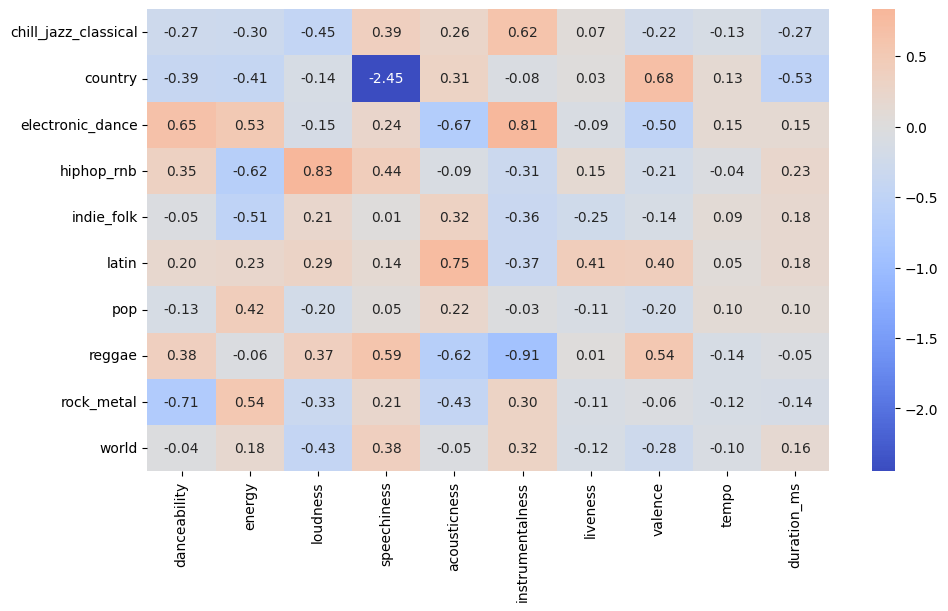

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print(coefs.abs().mean().sort_values(ascending=False))

plt.figure(figsize=(11, 6))
sns.heatmap(coefs, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

Would say it's better to keep all features to have more data to determine genre

# Results

In [16]:
# scaling training data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)           # reuse train's mean/std
X_test_s = scaler.transform(X_test)

model = LogisticRegression(class_weight=None, max_iter=2000)
model.fit(X_train_s, y_train)

pred = model.predict(X_val_s)
print(classification_report(y_val, pred))

                      precision    recall  f1-score   support

chill_jazz_classical       0.46      0.56      0.50      4152
             country       0.33      0.14      0.20      1170
    electronic_dance       0.46      0.70      0.55      7728
          hiphop_rnb       0.39      0.03      0.06      1541
          indie_folk       0.12      0.00      0.00      1000
               latin       0.37      0.47      0.42      3671
                 pop       0.27      0.16      0.20      4387
              reggae       0.16      0.02      0.04       776
          rock_metal       0.41      0.56      0.47      6737
               world       0.21      0.02      0.03      3155

            accuracy                           0.41     34317
           macro avg       0.32      0.27      0.25     34317
        weighted avg       0.37      0.41      0.36     34317



In [18]:
print(classification_report(y_test, model.predict(X_test_s)))

                      precision    recall  f1-score   support

chill_jazz_classical       0.46      0.56      0.50      2076
             country       0.30      0.12      0.17       585
    electronic_dance       0.47      0.71      0.57      3864
          hiphop_rnb       0.34      0.03      0.05       770
          indie_folk       0.33      0.00      0.00       501
               latin       0.36      0.47      0.41      1835
                 pop       0.25      0.15      0.19      2193
              reggae       0.15      0.02      0.04       388
          rock_metal       0.41      0.57      0.48      3369
               world       0.23      0.02      0.03      1578

            accuracy                           0.42     17159
           macro avg       0.33      0.26      0.24     17159
        weighted avg       0.37      0.42      0.36     17159

